In [291]:
%matplotlib widget
import importlib
import numpy as np
import scipy as sc
from mpl_toolkits.mplot3d import Axes3D
import os
import matplotlib.pyplot as plt
import time
import pandas as pd

#Mes imports

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Simulations')
import nano_objects
importlib.reload(nano_objects)
from nano_objects import *


os.chdir(r'C:\Users\nberr\Documents\Code\python\Modules')
import Slider_plot
importlib.reload(Slider_plot)
from Slider_plot import *
import Slider_plot_v2
importlib.reload(Slider_plot_v2)
from Slider_plot_v2 import *

from matplotlib.widgets import Slider, Button


## Create a Nano_objecterial class for future implementation

get gold index data

Get data

In [292]:
os.chdir(r'H:\commun\Utilisateur FNO\Nathan\COMSOL\Data_refractive_index')
data = pd.read_csv('GaP - Aspnes.csv', skiprows=1).__array__()


Lda = data[:,0]*1e-6
Au_n = data[:,1]
Au_k = data[:,2]

interpolate data

In [293]:
n = sc.interpolate.interp1d(Lda, Au_n, kind='cubic', bounds_error=False, fill_value=1)
k = sc.interpolate.interp1d(Lda, Au_k, kind='cubic', bounds_error=False, fill_value=0)

Lambda = np.linspace(400e-9, 800e-9, 1000)

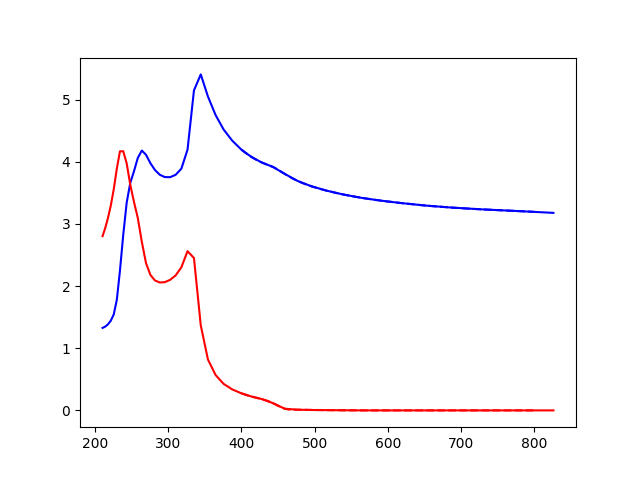

In [294]:
fig = plt.figure()

plt.plot(Lda*1e9, Au_n, color='b', label = 'n')
plt.plot(Lda*1e9, Au_k, color='r', label = 'k')

plt.plot(Lambda*1e9, n(Lambda), color='b', linestyle = '--')
plt.plot(Lambda*1e9, k(Lambda), color='r', linestyle = '--')

Create objects

In [ ]:
a= 500e-9
c = 125e-9
eps_ext = 1.305**2 * np.ones(np.size(Lambda))


Gold_sphere = Sphere(r=a, wl = Lambda, n = n(Lambda), k = k(Lambda), name = 'Gold', eps_ext= eps_ext)
Gold_ellipse = Ellipsoid(a=a, c=c, wl = Lambda, n = n(Lambda), k = k(Lambda), name = 'Gold', polar=(1,0,0), eps_ext= eps_ext)


print(Gold_ellipse.lda_SPR*1e9)


400.0


In [296]:
polar=(1,0,0)

Lambda = Gold_ellipse.wl

alpha_1 = Gold_sphere.polarizability
alpha_2 = Gold_ellipse.polarizability
sigma_abs1 = Gold_sphere.sigma_abs 
sigma_abs2 = Gold_ellipse.sigma_abs 

sigma_sca1 =  Gold_sphere.sigma_scat
sigma_sca2 =  Gold_ellipse.sigma_scat

sigma_ext1 = Gold_sphere.sigma_abs + Gold_sphere.sigma_scat
sigma_ext2 = Gold_ellipse.sigma_abs + Gold_ellipse.sigma_scat

Polarizability definition

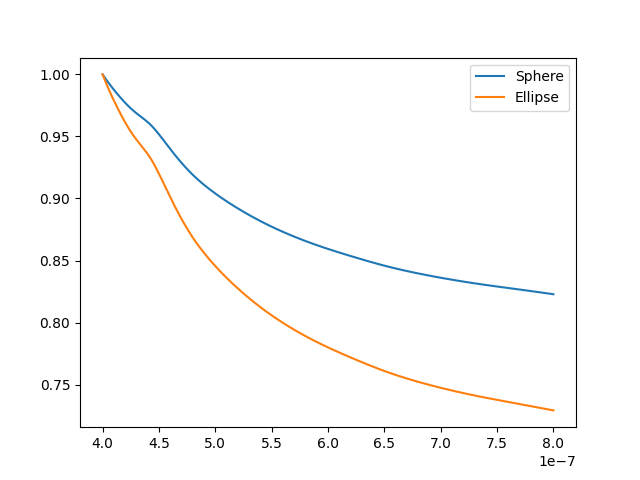

In [297]:
fig = plt.figure()

res_sphere = np.abs(Gold_sphere.polarizability)
res_ellipse = np.abs(Gold_ellipse.polarizability)

plt.plot(Gold_sphere.wl, res_sphere / np.max(res_sphere), label='Sphere' )
plt.plot(Gold_ellipse.wl, res_ellipse/np.max(res_ellipse), label='Ellipse')
plt.legend()


<>:5: SyntaxWarning: invalid escape sequence '\s'
<>:5: SyntaxWarning: invalid escape sequence '\s'
C:\Users\nberr\AppData\Local\Temp\ipykernel_5568\2180354872.py:5: SyntaxWarning: invalid escape sequence '\s'
  plt.ylabel('$\sigma_{ext}$ (um$^2$)')


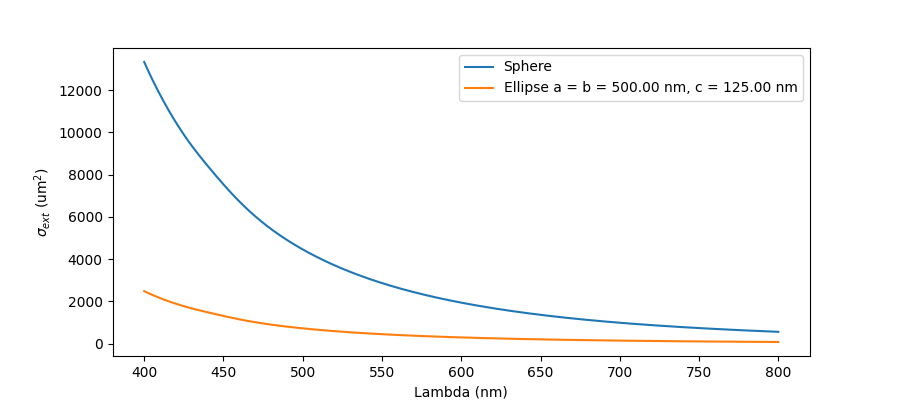

In [ ]:
fig = plt.figure(figsize=(9,4))
plt.plot(Lambda*1e9, sigma_ext1*1e12, label='Sphere')
plt.plot(Lambda*1e9, sigma_ext2*1e12, label='Ellipse a = b = {:.2f} nm, c = {:.2f} nm'.format(a*1e9, c*1e9))
plt.xlabel('Lambda (nm)')
plt.ylabel('$\sigma_{ext}$ (um$^2$)')
plt.legend()

<>:5: SyntaxWarning: invalid escape sequence '\s'
<>:5: SyntaxWarning: invalid escape sequence '\s'
C:\Users\nberr\AppData\Local\Temp\ipykernel_5568\4007669367.py:5: SyntaxWarning: invalid escape sequence '\s'
  plt.ylabel('$\sigma_{abs}$ (um$^2$)')


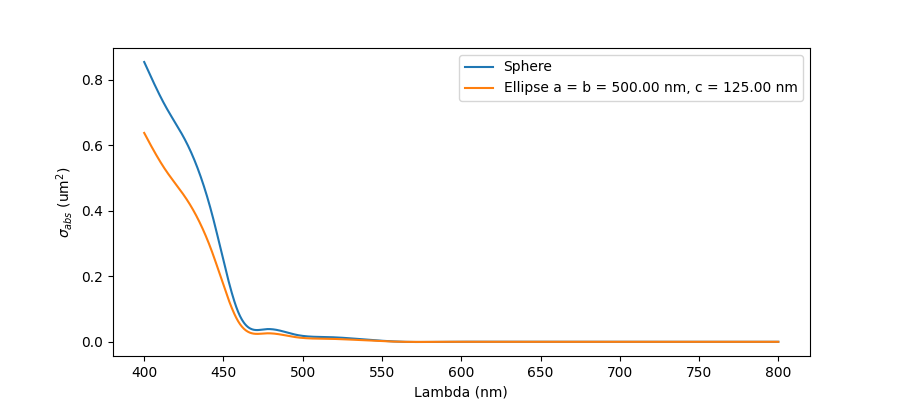

In [299]:
fig = plt.figure(figsize=(9,4))
plt.plot(Lambda*1e9, sigma_abs1*1e12, label='Sphere')
plt.plot(Lambda*1e9, sigma_abs2*1e12, label='Ellipse a = b = {:.2f} nm, c = {:.2f} nm'.format(a*1e9, c*1e9))
plt.xlabel('Lambda (nm)')
plt.ylabel('$\sigma_{abs}$ (um$^2$)')
plt.legend()

Text(0.5, 1.0, 'Ellipsoid')

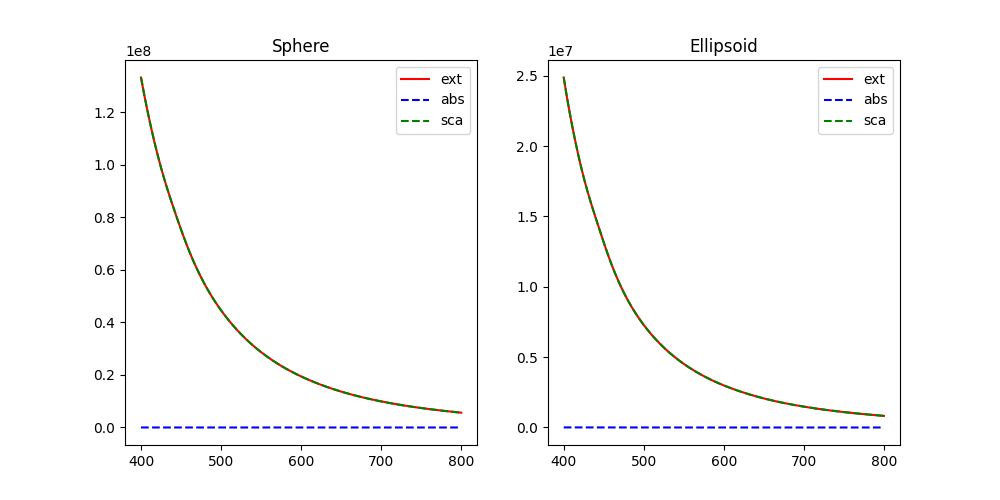

In [ ]:
fig ,ax = plt.subplots(ncols=2, figsize=(10, 5))

ax[0].plot(Lambda*1e9, sigma_ext1*1e16, color='r', label='ext')
ax[0].plot(Lambda*1e9, sigma_abs1*1e16, color='b', linestyle='--', label='abs')
ax[0].plot(Lambda*1e9, sigma_sca1*1e16, color='g', linestyle='--', label='sca')
ax[0].legend()
ax[0].set_title('Sphere')

ax[1].plot(Lambda*1e9, sigma_ext2*1e16, color='r', label='ext')
ax[1].plot(Lambda*1e9, sigma_abs2*1e16, color='b', linestyle='--', label='abs')
ax[1].plot(Lambda*1e9, sigma_sca2*1e16, color='g', linestyle='--', label='sca')
ax[1].legend()
ax[1].set_title('Ellipsoid')

Text(0.5, 1.0, 'Sphere')

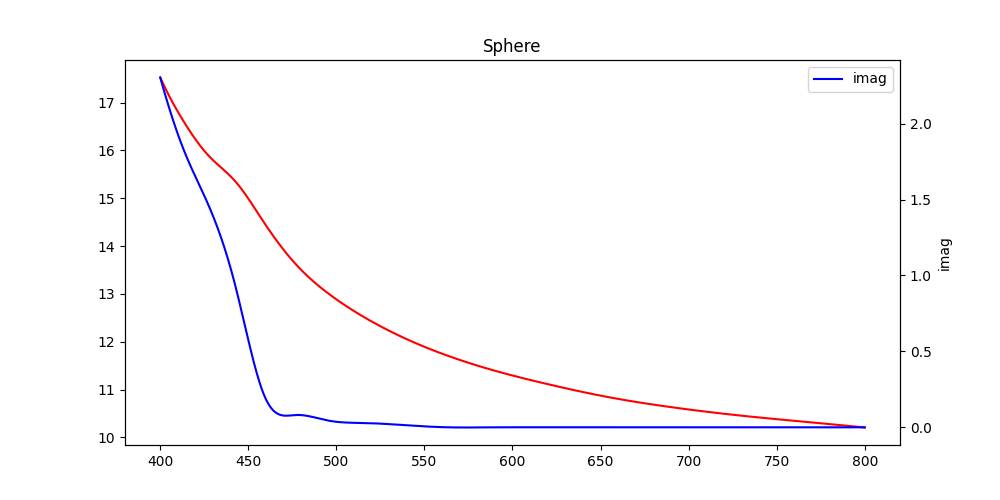

In [ ]:
fig = plt.figure(figsize=(10, 5))

plt.plot(Lambda*1e9, Gold_sphere.eps_1, color='r', label='real')
axx = plt.twinx()
axx.plot(Lambda*1e9, Gold_sphere.eps_2, color='b', label='imag')

plt.ylabel('imag')
plt.legend()
axx.legend()
plt.title('Sphere')

Text(0.5, 1.0, 'Sphere')

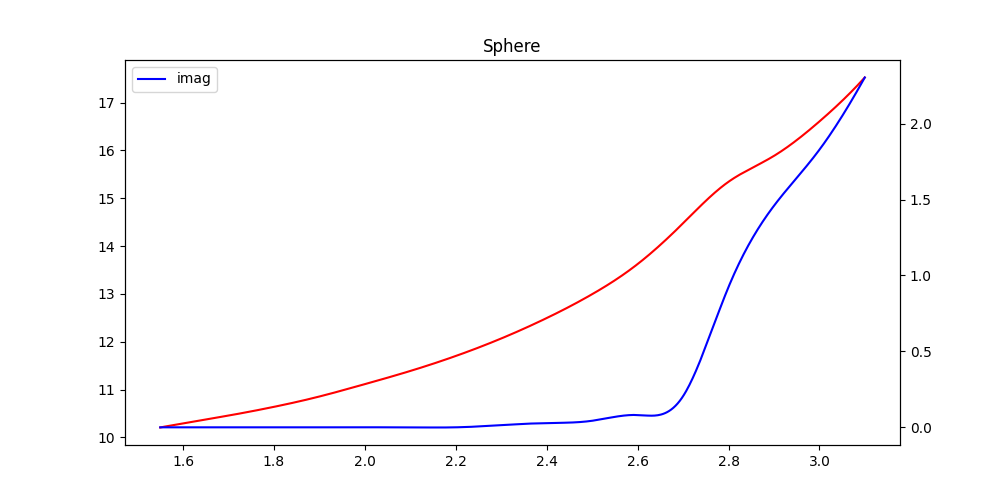

In [302]:

h = sc.constants.h 
c = sc.constants.c 
eV = sc.constants.e 
Energy = h*c/Lambda

fig = plt.figure(figsize=(10, 5))

plt.plot(Energy/eV, Gold_sphere.eps_1, color='r', label='real')
axx = plt.twinx()
axx.plot(Energy/eV, Gold_sphere.eps_2, color='b', label='imag')

plt.legend()
axx.legend()
plt.title('Sphere')

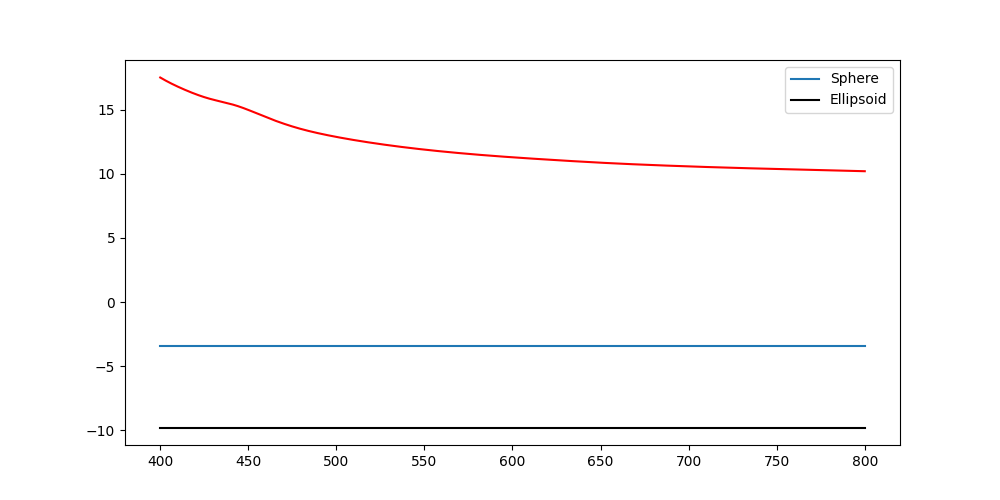

In [303]:
fig = plt.figure(figsize=(10, 5))

plt.plot(Lambda*1e9, Gold_sphere.eps_1, color='r')


L1 = Gold_sphere.L
H1 = (1-L1)/L1

L2 = Gold_ellipse.L
H2 = (1-L2)/L2

plt.plot(Lambda*1e9, -H1*eps_ext, label='Sphere')
plt.plot(Lambda*1e9, -H2*eps_ext, label='Ellipsoid', color='black')

plt.legend()